# Gerchberg-Saxton ponderado de fase fija contra slmsuite

**Pregunta:** ¿Iguala el Gerchberg-Saxton ponderado de fase fija de DinHot al estado del arte, los algoritmos ponderados de slmsuite ejecutados sobre el mismo objetivo y la misma grilla de 1024 trampas, en eficiencia, uniformidad y número de iteraciones para llegar?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** notebook 02 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

En arreglos de miles de sitios, como los 6.100 átomos en unas 12.000 pinzas de trabajos recientes, la uniformidad del algoritmo ponderado es el límite del experimento, y el campo se asentó en un algoritmo práctico: Gerchberg-Saxton ponderado que congela la fase del plano focal después de una docena de iteraciones (Kim et al. 2019). DinHot lo implementa como M07. La afirmación que se prueba no es que DinHot supere a alguien: es que su implementación es un miembro fiel del estado del arte, de modo que todo notebook posterior pueda usarla como línea base. Ejecutarás M06 y M07 en las 1024 trampas del caso C03, ejecutarás slmsuite 0.5.0, una biblioteca de código abierto con los mismos algoritmos, con sus pesos de Leonardo y de Kim sobre las mismas trampas, la misma grilla FFT y el mismo haz gaussiano, evaluarás todos con las mismas métricas y leerás la diferencia en la figura y en la tabla.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 slmsuite==0.5.0
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# the tools and their versions, the pipeline's modules by path, and the pinned reference implementation
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
import slmsuite
from slmsuite.holography.algorithms import SpotHologram

slmsuite.configure_logging(None)  # no console log inside the outputs

for name in ("numpy", "matplotlib", "slmsuite"):
    print(name, md.version(name))


def trap_numbers(phi, setup, traps):
    """Efficiency, uniformity and relative spread (percent) of a hologram, read on the FFT grid."""
    v = forward.trap_fields_from_fft(forward.fft_focal_field(phi, setup), setup, traps)
    i = metrics.trap_intensities(v)
    return metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)


def first_below(curve, percent):
    """The first iteration (1-based) whose spread is below ``percent``, or None."""
    return next((k + 1 for k, row in enumerate(curve) if row[2] < percent), None)

numpy 2.4.6
matplotlib 3.11.2
slmsuite 0.5.0


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot, para el caso; slmsuite es una biblioteca de código abierto para holografía con SLM, licencia MIT, fijada en 0.5.0 (https://pypi.org/project/slmsuite/).
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros; la implementación de referencia se usa como biblioteca bajo su propia licencia.
- Archivo leído: `data/examples/cases.json`, caso C03, una red de 32 por 32 con 1024 trampas sobre el SLM de 256 por 256 píxeles, con la semilla del caso y la siguiente.

In [2]:
# case C03: 1024 traps, 32 x 32, on the 256 x 256 pixel SLM; both implementations get this array and this beam
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C03_large_array"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
seeds = [rec["seed"], rec["seed"] + 1]
iy, ix = forward.trap_bins(setup, traps)
spots = np.vstack([ix, iy])
print(f"{len(traps)} trampas, bin focal {geometry.focal_bin_m(setup) * 1e6:.3f} um")
print(f"{rec['budget']['iterations']} iteraciones del presupuesto")
print(f"trampas por píxel del SLM: {len(traps) / setup.n_pix**2 * 100:.2f} % de los píxeles")

1024 trampas, bin focal 0.498 um
30 iteraciones del presupuesto
trampas por píxel del SLM: 1.56 % de los píxeles


## Método

La actualización ponderada del notebook 02 es $w_m \leftarrow w_m \langle r\rangle/r_m$ con $r_m = |V_m|/a_m$, y el pedido es $c_m = w_m a_m e^{i\psi_m}$ con $\psi_m = \arg V_m$ (Di Leonardo et al. 2007, https://doi.org/10.1364/OE.15.001913). La variante de fase fija (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178; M07 en el producto) sigue al campo durante las primeras $N$ iteraciones, $\psi_i = \arg V_m^{i}$, y luego lo congela, $\psi_i = \psi_N$ para $i \geq N$, de modo que las iteraciones posteriores solo ajustan amplitudes. Kim informa una eficiencia de modulación de 91,2 por ciento para 1500 focos con $N = 12$; el producto toma $N = 12$ como valor por defecto. Con 1024 trampas sobre un SLM de 256 por 256 hay 64 píxeles por trampa, de modo que es un holograma apretado, que es el régimen donde el algoritmo importa. Las celdas siguientes ejecutan los dos métodos ponderados del producto desde los mismos inicios aleatorios y preguntan cuándo ayuda congelar.

La primera celda ejecuta Gerchberg-Saxton ponderado (M06) y la variante de fase fija (M07) durante las 30 iteraciones del caso, con dos semillas cada una. Informa el promedio de la eficiencia, la uniformidad y la dispersión finales sobre las semillas y la primera iteración en que la dispersión de cada semilla baja de 1 por ciento.

In [3]:
# DinHot: weighted GS (M06) and phase-fixed WGS (M07, the phase is frozen after 12 iterations), two seeds each
budget = Budget(rec["budget"]["iterations"])
product = {"M06": [], "M07": []}
for seed in seeds:
    product["M06"].append(m06_gsw.run(setup, target, budget=budget, rng=Rng(seed)))
    product["M07"].append(m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(seed)))
for name, results in product.items():
    curve = [[(h["efficiency"], h["uniformity"], h["rel_std"]) for h in res.history] for res in results]
    final = np.mean([c[-1] for c in curve], axis=0)
    print(f"{name}: e = {final[0]:.4f}, u = {final[1]:.4f}, sigma = {final[2]:.3f} %")
    print(f"     primera iteración bajo 1 por ciento, por semilla: {[first_below(c, 1.0) for c in curve]}")

M06: e = 0.8059, u = 0.9576, sigma = 1.299 %
     primera iteración bajo 1 por ciento, por semilla: [None, None]
M07: e = 0.7943, u = 0.9908, sigma = 0.309 %
     primera iteración bajo 1 por ciento, por semilla: [15, 15]


La iteración de congelamiento es un parámetro, y el valor por defecto del producto es el publicado. La celda ejecuta M07 con $N$ igual a 6, 12 y 20 con la primera semilla e imprime la dispersión en las iteraciones 12, 20 y 30, para ver qué compra el valor por defecto en este arreglo.

In [4]:
# when to freeze: n_fix = 6, 12 and 20 iterations before the focal phase is held
frozen = {}
for n_fix in (6, 12, 20):
    res = m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(seeds[0]), n_fix=n_fix)
    frozen[n_fix] = [h["rel_std"] for h in res.history]
    at = [frozen[n_fix][k - 1] for k in (12, 20, 30)]
    print(f"n_fix = {n_fix:2d}: sigma en la iteración 12, 20, 30 = " + ", ".join(f"{x:.3f}" for x in at) + " %")

n_fix =  6: sigma en la iteración 12, 20, 30 = 1.412, 1.360, 1.305 %
n_fix = 12: sigma en la iteración 12, 20, 30 = 3.313, 0.331, 0.273 %
n_fix = 20: sigma en la iteración 12, 20, 30 = 3.313, 1.997, 0.180 %


## Estado del arte

slmsuite es una biblioteca de Python de código abierto para calcular hologramas en SLM. Su `SpotHologram` recibe una lista de puntos en las coordenadas de píxel del plano de Fourier con relleno (la base knm), la amplitud del haz sobre el SLM y la forma de la grilla de cálculo, y su `optimize` trae por nombre los métodos ponderados de la literatura: `WGS-Leonardo` implementa la actualización de Di Leonardo et al. con una potencia $p$ sobre la razón de amplitudes, y `WGS-Kim` fija la fase después de `fix_phase_iteration` iteraciones. Las entradas de abajo son las del producto: los mismos 1024 bins de la misma grilla de 512 por 512, el mismo haz gaussiano normalizado, una fase de 256 por 256, 30 iteraciones y un inicio aleatorio sembrado por numpy. Todas las otras opciones quedan en su valor por defecto de slmsuite, de modo que una diferencia puede venir de una elección que los dos códigos hacen distinta, como el exponente de la actualización de pesos, y no solo del algoritmo. Ambas implementaciones se leen con la misma función: la fase que devuelve slmsuite se transforma con el modelo directo de DinHot y las trampas se leen en sus bins.

La celda construye un `SpotHologram` por corrida, ejecuta 30 iteraciones de `WGS-Leonardo` y de `WGS-Kim` para cada una de las dos semillas, y guarda con un callback la fase que usó cada iteración, para poder dibujar la dispersión contra la iteración. Luego evalúa cada fase guardada con las métricas del producto. El registro de slmsuite se apaga al importar para que la celda imprima solo lo que imprime el notebook.

In [5]:
# slmsuite on the same target: the same spots on the same 512 x 512 grid, the same Gaussian beam, a random start
beam = geometry.input_amplitude(setup)
size = setup.n_fft
reference = {"WGS-Leonardo": [], "WGS-Kim": []}
final_phase = {}
for method in reference:
    for seed in seeds:
        np.random.seed(seed)
        holo = SpotHologram(shape=(size, size), spot_vectors=spots, basis="knm", spot_amp=np.ones(len(traps)),
                            cameraslm=None, slm_shape=(setup.n_pix, setup.n_pix), amp=beam)
        phases = []
        holo.optimize(method=method, maxiter=30, verbose=False, fix_phase_iteration=12,
                      callback=lambda h: phases.append(np.array(h.phase, dtype=float)))
        phases.append(np.array(holo.get_phase(), dtype=float))
        final_phase[(method, seed)] = phases[-1]
        reference[method].append([trap_numbers(p, setup, traps) for p in phases[1:]])
print({m: len(v) for m, v in reference.items()}, "corridas de cada método")

{'WGS-Leonardo': 2, 'WGS-Kim': 2} corridas de cada método


La celda siguiente pone los cuatro métodos en una tabla: la eficiencia, la uniformidad y la dispersión finales promediadas sobre las dos semillas y la primera iteración en que la dispersión de cada semilla queda bajo 1 por ciento.

In [6]:
# the final numbers of every run on one table, read with DinHot's own metrics
rows = {}
for name, results in product.items():
    rows[name] = [[(h["efficiency"], h["uniformity"], h["rel_std"]) for h in res.history] for res in results]
for method, curves in reference.items():
    rows["slmsuite " + method] = curves
for name, curves in rows.items():
    final = np.mean([c[-1] for c in curves], axis=0)
    need = [first_below(c, 1.0) for c in curves]
    print(f"{name:22s} e = {final[0]:.4f}  u = {final[1]:.4f}  sigma = {final[2]:6.3f} %")
    print(f"{'':22s} primera iteración bajo 1 por ciento, por semilla: {need}")

M06                    e = 0.8059  u = 0.9576  sigma =  1.299 %
                       primera iteración bajo 1 por ciento, por semilla: [None, None]
M07                    e = 0.7943  u = 0.9908  sigma =  0.309 %
                       primera iteración bajo 1 por ciento, por semilla: [15, 15]
slmsuite WGS-Leonardo  e = 0.8056  u = 0.9459  sigma =  1.664 %
                       primera iteración bajo 1 por ciento, por semilla: [None, None]
slmsuite WGS-Kim       e = 0.7926  u = 0.9943  sigma =  0.211 %
                       primera iteración bajo 1 por ciento, por semilla: [17, 17]


La primera figura grafica la dispersión relativa contra la iteración para la primera semilla de cada uno de los cuatro métodos, en un eje logarítmico. La línea vertical punteada marca la iteración 12, donde los dos métodos de fase fija congelan la fase focal.

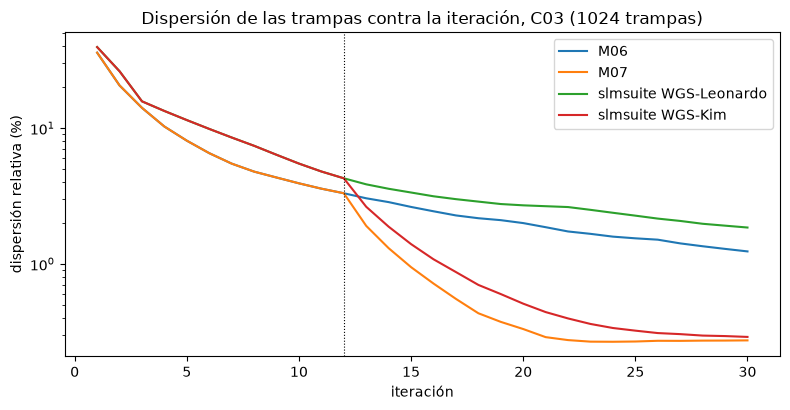

In [7]:
# the spread against the iteration, first seed of each method, on a log axis
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, curves in rows.items():
    ax.semilogy(np.arange(1, 31), [row[2] for row in curves[0]], label=name)
ax.axvline(12, color="k", ls=":", lw=0.8)
ax.set_xlabel("iteración")
ax.set_ylabel("dispersión relativa (%)")
ax.set_title("Dispersión de las trampas contra la iteración, C03 (1024 trampas)")
ax.legend()
fig.tight_layout()
plt.show()

Las curvas bajan juntas durante las primeras doce iteraciones, que son la misma actualización ponderada en los cuatro, y las dos curvas de slmsuite quedan algo sobre las de DinHot (cerca de 4,3 frente a 3,3 por ciento en la iteración 12), porque slmsuite parte de una fase aleatoria y DinHot de la superposición de fases aleatorias; la figura no puede separar el efecto del inicio del efecto del código. En la línea punteada M07 y WGS-Kim se doblan hacia abajo de inmediato, mientras M06 y WGS-Leonardo, la misma actualización sin congelar, siguen despacio: ese es el efecto de congelar la fase. Tras el quiebre M07 cae más rápido que WGS-Kim durante cerca de diez iteraciones y luego ambos se aplanan en cerca de 0,3 por ciento. La figura muestra una semilla; la tabla, que promedia dos, dice cuánto de la diferencia final es del algoritmo y cuánto del inicio.

La segunda figura dibuja el histograma de las 1024 potencias de las trampas, divididas por su promedio, tras 30 iteraciones, para M07 y para WGS-Kim de slmsuite con la primera semilla.

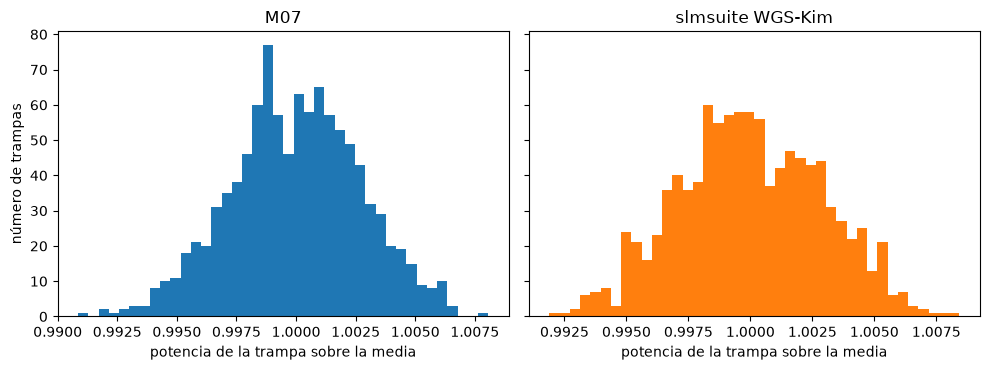

In [8]:
# the power of the 1024 traps after 30 iterations, M07 and slmsuite's WGS-Kim, relative to the mean
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
shown = (("M07", product["M07"][0].phi), ("slmsuite WGS-Kim", final_phase[("WGS-Kim", seeds[0])]))
for ax, (name, phi) in zip(axes, shown):
    i = metrics.trap_intensities(forward.trap_fields_from_fft(forward.fft_focal_field(phi, setup), setup, traps))
    ax.hist(i / i.mean(), bins=40, color="C0" if name == "M07" else "C1")
    ax.set_title(name)
    ax.set_xlabel("potencia de la trampa sobre la media")
axes[0].set_ylabel("número de trampas")
fig.tight_layout()
plt.show()

Ambos histogramas tienen forma de campana y son angostos: casi todas las trampas quedan a menos de 0,7 por ciento de la potencia media, y los dos extremos difieren en cerca de 1,7 por ciento para M07 y cerca de 1,6 por ciento para slmsuite. Las formas coinciden. La diferencia de los promedios de la tabla, 0,309 frente a 0,211 por ciento de dispersión, es entonces una diferencia entre dos distribuciones angostas, y con dos semillas no puede decirse que sea sistemática. La figura muestra solo el estado final; no dice cuántas iteraciones necesita cada uno, que es lo que hace la última columna de la tabla.

## Resultados

**Respuesta:** Sí, dentro de la resolución de dos semillas. En las 1024 trampas de C03 el M07 de fase fija alcanza una eficiencia de 0,7943, una uniformidad de 0,9908 y una dispersión de 0,309 por ciento tras 30 iteraciones, y WGS-Kim de slmsuite alcanza 0,7926, 0,9943 y 0,211 por ciento sobre el mismo objetivo y la misma grilla; la eficiencia difiere en 0,0017 y ambos histogramas de potencias de trampas caben dentro de 1,7 por ciento. M07 necesita 15 iteraciones para bajar la dispersión de 1 por ciento, frente a 17 de WGS-Kim. Los métodos sin fase fija no llegan en 30 iteraciones: M06 termina en 1,299 por ciento y WGS-Leonardo de slmsuite en 1,664 por ciento. La iteración de congelamiento importa: con $N = 12$ la dispersión es 0,273 por ciento en la iteración 30, con $N = 6$ es 1,305 por ciento y con $N = 20$ es 0,180 por ciento. La implementación del producto es un miembro fiel del estado del arte; el notebook no muestra que sea mejor.

## Resumen

Congelar la fase focal tras una docena de iteraciones convierte la cola lenta de Gerchberg-Saxton ponderado en una caída rápida a unas pocas décimas de porcentaje, tanto en la implementación del producto como en la de slmsuite. Las dos coinciden en la eficiencia en dos partes por mil y en la dispersión en una décima de porcentaje, de modo que el M07 de DinHot puede ser la línea base de los notebooks posteriores sin pérdida. Lo que la comparación no cubre es la calidad de la regla de congelamiento en arreglos que no son apretados, con una cámara en el lazo o con un SLM que no es ideal: lo último es el tema del notebook siguiente, donde el modelo del dispositivo entra al lazo mismo.

## Referencias

- Kim, Kim, Lee y Ahn, "Gerchberg-Saxton algorithm with phase fixing for tweezer arrays", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- slmsuite 0.5.0 (MIT), https://pypi.org/pypi/slmsuite/json y https://pypi.org/project/slmsuite/.